0. Постановка задачи

Цель данной работы - исследовать возможность автоматического определения музыкального жанра композиции с помощью методов машинного обучения.

Для решения задачи используется датасет Spotify, содержащий информацию о 114 000 музыкальных композициях, относящихся к 114 различным жанрам.

Каждая композиция описывается набором характеристик, среди которых: популярность (`popularity`), продолжительность (`duration_ms`), танцевальность (`danceability`), энергичность (`energy`), громкость (`loudness`), акустичность (`acousticness`), инструментальность (`instrumentalness`), темп (`tempo`) и другие параметры.

В качестве целевой переменной используется `track_genre`, содержащая название музыкального жанра композиции. Остальные выбранные характеристики используются в качестве входных признаков, на основании которых модель должна определить жанр.

Задача заключается в построении модели, способной на основе известных характеристик музыкальной композиции предсказать одну из 114 возможных категорий.

Данная задача относится к обучению с учителем.Это многоклассовая классификация, так как целевая переменная может принимать более двух категориальных значений.

В качестве основного алгоритма классификации выбран KNN.

В ходе работы необходимо выполнить предварительную обработку данных, исследовать статистические характеристики и распределения признаков, проверить наличие выбросов и пропущенных значений, преобразовать категориальные переменные.

После подготовки данных необходимо обучить классификатор KNN, подобрать оптимальное количество ближайших соседей и оценить качество его работы на обучающей и тестовой выборках.

Для оценки результатов будем использовать Accuracy, Precision, Recall, F1-score, а также матрицы рассогласования, позволяющие определить, насколько успешно модель распознаёт различные музыкальные жанры.

Необходимо выяснить насколько эффективно характеристики музыкальных композиций могут использоваться для автоматической классификации жанров с помощью алгоритма ближайших соседей.

In [49]:
import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")

print(path)

C:\Users\dimka\.cache\kagglehub\datasets\maharshipandya\-spotify-tracks-dataset\versions\1


1.read info and do some stuff to know dataset

In [50]:
csv_path = os.path.join(path, "dataset.csv")
df = pd.read_csv(csv_path)
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [51]:
print("Dataset shape:", df.shape)
print("\nColumn names:\n",df.columns.tolist())
df = df.drop(columns=["Unnamed: 0"], errors="ignore") #remove same tech index
df.head()
df.info()

Dataset shape: (114000, 21)

Column names:
 ['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  object 
 1   artists           113999 non-null  object 
 2   album_name        113999 non-null  object 
 3   track_name        113999 non-null  object 
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  i

2. Split the data into training and test sets  
We  will split the dataset into  80/20.  80% on train and 20% on test

In [52]:
import numpy as np
from sklearn.model_selection import train_test_split

target = "track_genre"

numerical_features = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

categorical_features = [
    "explicit",
    "key",
    "mode",
    "time_signature"
]

feature_columns = numerical_features + categorical_features

# check needed existed colums
required_columns = feature_columns + [target]

missing_columns = [ col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Отсутствуют столбцы: {missing_columns}")

#delete duplicates
print("amount of full duplicates:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# delete the strings which is missing the target var
df = df.dropna(subset=[target]).copy()

X = df[feature_columns].copy()

#rplace inf to nan
X = X.replace([np.inf, -np.inf], np.nan)

y = df[target].astype(str)

# devide ds
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("train set:", X_train.shape)
print("test set:", X_test.shape)

print("\n distrbution of genres in traing set:")
display(y_train.value_counts().head(10))

print("\n distrbution of genres in traing set")
display(y_test.value_counts().head(10))

amount of full duplicates: 450
train set: (90840, 15)
test set: (22710, 15)

 distrbution of genres in traing set:


track_genre
indie-pop     800
samba         800
electronic    800
songwriter    800
r-n-b         800
reggaeton     800
garage        800
synth-pop     800
acoustic      800
mpb           800
Name: count, dtype: int64


 distrbution of genres in traing set


track_genre
turkish          200
afrobeat         200
emo              200
chicago-house    200
mandopop         200
indie-pop        200
j-pop            200
ska              200
sad              200
k-pop            200
Name: count, dtype: int64

3. visualize information and get main stats from info

In [53]:
print("Number of rows:", len(df))
print("Number of features used by the model:", len(feature_columns))
print("Number of genres:", y.nunique())

print("\nDescriptive statistics for numerical features:")
display(df[numerical_features].describe().T)

print(y.value_counts().describe())

Number of rows: 113550
Number of features used by the model: 15
Number of genres: 114

Descriptive statistics for numerical features:


,count,mean,std,min,25%,50%,75%,max
popularity,113550.0,33.324139,22.283976,0.000,17.00000,35.000000,50.000000,100.000
duration_ms,113550.0,228079.362202,106414.782554,0.000,174180.25000,213000.000000,261587.750000,5237295.000
danceability,113550.0,0.567031,0.173408,0.000,0.45600,0.580000,0.695000,0.985
energy,113550.0,0.642090,0.251052,0.000,0.47300,0.685000,0.854000,1.000
loudness,113550.0,-8.243419,5.011401,-49.531,-9.99775,-6.997000,-5.001000,4.532
speechiness,113550.0,0.084674,0.105761,0.000,0.03590,0.048900,0.084500,0.965
acousticness,113550.0,0.314067,0.331907,0.000,0.01680,0.168000,0.596000,0.996
instrumentalness,113550.0,0.155702,0.309216,0.000,0.00000,0.000041,0.048675,1.000
liveness,113550.0,0.213611,0.190461,0.000,0.09800,0.132000,0.273000,1.000
valence,113550.0,0.474207,0.259204,0.000,0.26000,0.464000,0.683000,0.995


count     114.000000
mean      996.052632
std        11.846244
min       904.000000
25%       998.000000
50%       999.000000
75%      1000.000000
max      1000.000000
Name: count, dtype: float64


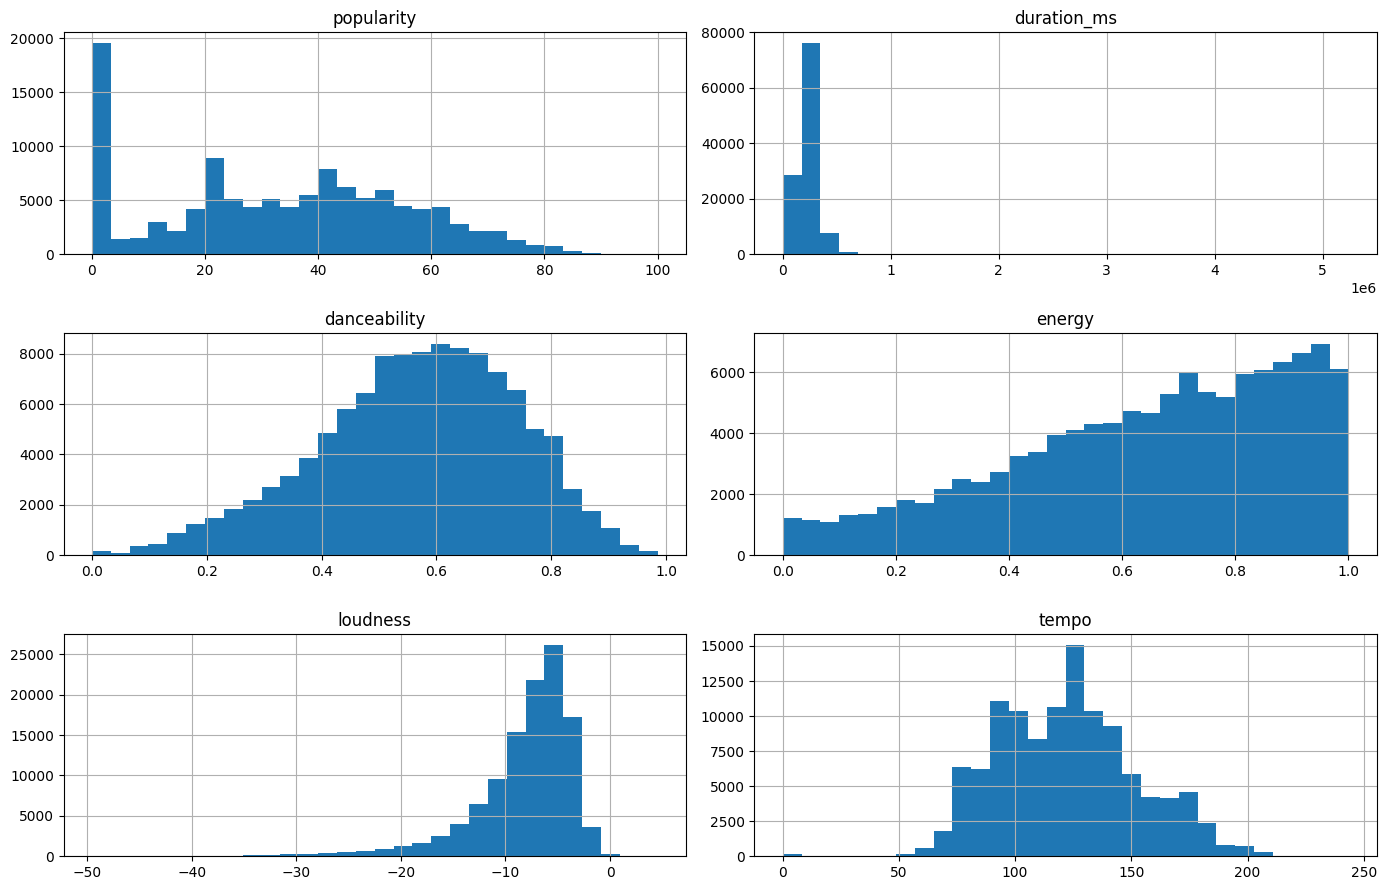

In [54]:
import matplotlib.pyplot as plt
histogram_features = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "tempo"
]

df[histogram_features].hist(
    bins=30,
    figsize=(14, 9)
)

plt.tight_layout()
plt.show()

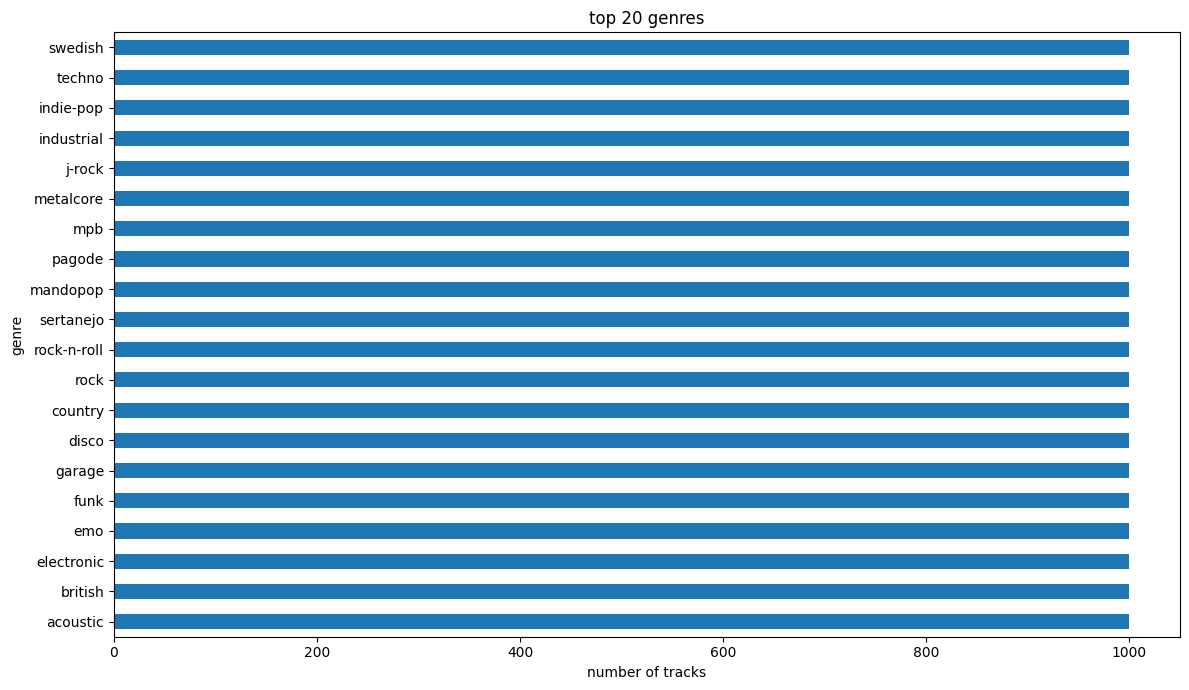

least frequent genres


track_genre
opera         992
hip-hop       991
kids          991
latin         990
iranian       988
honky-tonk    981
dance         965
german        963
classical     933
romance       904
Name: count, dtype: int64

In [55]:
genre_counts = df[target].value_counts()

plt.figure(figsize=(12, 7))

genre_counts.head(20).sort_values().plot(kind="barh")

plt.title("top 20 genres")
plt.xlabel("number of tracks")
plt.ylabel("genre")
plt.tight_layout()
plt.show()

print("least frequent genres")
display(genre_counts.tail(10))

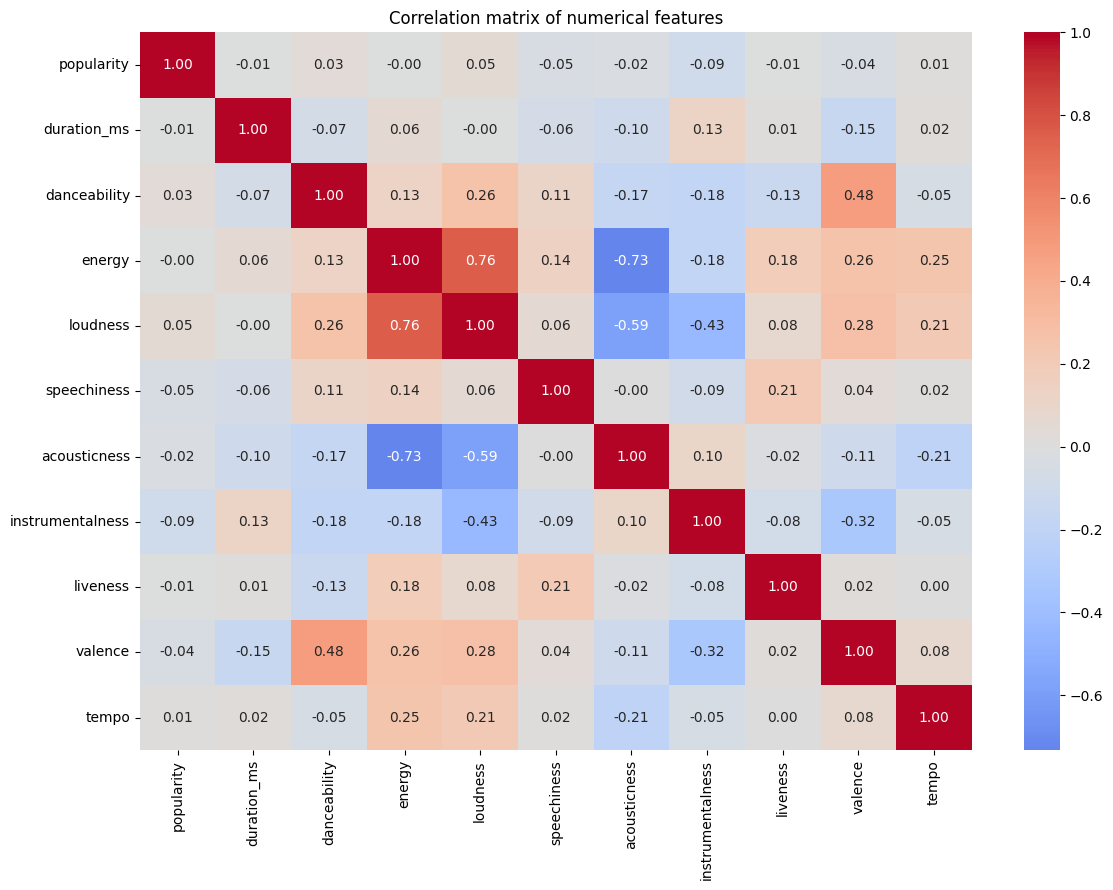

In [56]:
#correlation_matrix
import seaborn as sns

correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation matrix of numerical features")
plt.tight_layout()
plt.show()

4. Выбросы
Для обозначения выбросов будем использовать IQR

будем считать что выброс это когда у нас выполняется одно из двух условий
значение которые меньше Q1 - 1.5 * IQR
или
значение которое больше Q3 + 1.5 * IQR ( где Q1 и Q3 - 1 и 3 квартиль)

In [57]:
outlier_results = []

for col in numerical_features:
    values = X_train[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (X_train[col] < lower_bound)
        | (X_train[col] > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())

    outlier_results.append({
        "feature": col,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percent": 100 * outlier_count / len(X_train)
    })

outlier_table = pd.DataFrame(outlier_results)

display(
    outlier_table.sort_values(
        "outlier_percent",
        ascending=False
    )
)

,feature,lower_bound,upper_bound,outlier_count,outlier_percent
7,instrumentalness,-0.072000,0.120000,20105,22.132321
5,speechiness,-0.037300,0.157900,10547,11.610524
8,liveness,-0.164250,0.535350,6926,7.624395
4,loudness,-17.480000,2.488000,4917,5.412814
1,duration_ms,43141.000000,392525.000000,4474,4.925143
2,danceability,0.097500,1.053500,490,0.539410
10,tempo,38.070875,201.261875,486,0.535007
0,popularity,-32.500000,99.500000,2,0.002202
3,energy,-0.098500,1.425500,0,0.000000
6,acousticness,-0.850500,1.462300,0,0.000000


We will not delete the outlier results cause in our data they are not that bigger (by percentage) and this persent also can be interpreted as normal for some music genres 

5. find and handle missed values

In [58]:
missing_summary = pd.DataFrame({
    "train_missing": X_train.isna().sum(),
    "train_missing_percent": X_train.isna().mean() * 100,
    "test_missing": X_test.isna().sum(),
    "test_missing_percent": X_test.isna().mean() * 100
})

display(
    missing_summary[
        (missing_summary["train_missing"] > 0)
        | (missing_summary["test_missing"] > 0)
    ]
)

if not X_train.isna().any().any() and not X_test.isna().any().any():
    print("No missing values in the selected model features")
else:
    print("Missing values exist and will be handled")

,train_missing,train_missing_percent,test_missing,test_missing_percent


No missing values in the selected model features


6. handle the categorial features

We use one-hot encoding for the categorical features ( cause knn requires it). This creates
indicator columns for the observed categories.


In [59]:
for col in categorical_features:
    print(df[col].value_counts(dropna=False).head(15))

explicit
False    103832
True       9718
Name: count, dtype: int64
key
7     13200
0     13006
2     11594
9     11264
1     10740
5      9325
11     9251
4      8971
6      7891
10     7423
8      7337
3      3548
Name: count, dtype: int64
mode
1    72429
0    41121
Name: count, dtype: int64
time_signature
4    101487
3      9128
5      1805
1       967
0       163
Name: count, dtype: int64


7. normalize the numerical features 

In [60]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing:
# 1. Fill missing values with the median.
# 2. Standardize the numerical features.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# 1. Fill missing values with the most frequent category.
# 2. Convert categories into indicator columns.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply each pipeline to the appropriate columns
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

8. We will use KNN because our target its not a number. k nearest neighbors is good choise for classiffication task.  

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'model__n_neighbors': 13}
Best cross-validation macro-F1: 0.16204462152733654


,param_model__n_neighbors,mean_test_score,std_test_score
0,3,0.127863,0.003888
1,5,0.142284,0.002542
2,7,0.154264,0.001810
3,9,0.156867,0.001956
4,11,0.161007,0.003186
5,13,0.162045,0.002187


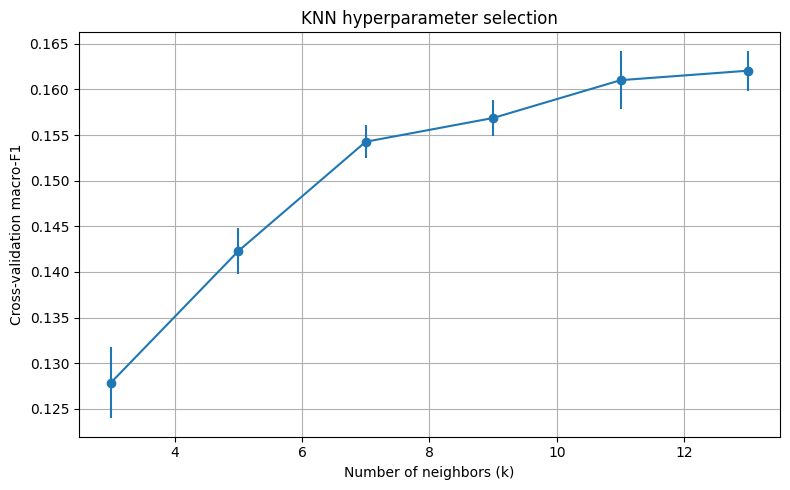

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [61]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, train_test_split

knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(n_jobs=-1))
])

tune_size = min(15000, len(X_train))

if tune_size < len(X_train):
    X_tune, _, y_tune, _ = train_test_split(
        X_train,
        y_train,
        train_size=tune_size,
        random_state=42,
        stratify=y_train
    )
else:
    X_tune = X_train
    y_tune = y_train

# Search for the best number of neighbors
param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 13]
}

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_tune, y_tune)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation macro-F1:", grid_search.best_score_)

# Inspect all tested values of k
cv_results = pd.DataFrame(grid_search.cv_results_)

cv_table = cv_results[[
    "param_model__n_neighbors",
    "mean_test_score",
    "std_test_score"
]].sort_values("param_model__n_neighbors")

display(cv_table)

plt.figure(figsize=(8, 5))

plt.errorbar(
    cv_table["param_model__n_neighbors"].astype(int),
    cv_table["mean_test_score"],
    yerr=cv_table["std_test_score"],
    marker="o"
)

plt.xlabel("Number of neighbors (k)")
plt.ylabel("Cross-validation macro-F1")
plt.title("KNN hyperparameter selection")
plt.grid(True)
plt.tight_layout()
plt.show()

# Retrain the best configuration using all training data
best_knn = grid_search.best_estimator_
best_knn.fit(X_train, y_train)

9. Calculate errors and confusion matrices

In [62]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predictions
knn_train_pred = best_knn.predict(X_train)
knn_test_pred = best_knn.predict(X_test)

# Calculate metrics
knn_train_accuracy = accuracy_score(y_train, knn_train_pred)
knn_test_accuracy = accuracy_score(y_test, knn_test_pred)

knn_train_error = 1 - knn_train_accuracy
knn_test_error = 1 - knn_test_accuracy

print("KNN evaluation\n")

print(f"Training accuracy: {knn_train_accuracy:.4f}")
print(f"Test accuracy:     {knn_test_accuracy:.4f}")

print(f"Training error:    {knn_train_error:.4f}")
print(f"Test error:        {knn_test_error:.4f}")

print(f"Test macro-F1:     {f1_score(y_test, knn_test_pred, average='macro'):.4f}")
print(f"Test weighted-F1:  {f1_score(y_test, knn_test_pred, average='weighted'):.4f}")

print("\nClassification report on test data:")

print(
    classification_report(
        y_test,
        knn_test_pred,
        zero_division=0
    )
)

KNN evaluation

Training accuracy: 0.3425
Test accuracy:     0.2098
Training error:    0.6575
Test error:        0.7902
Test macro-F1:     0.2011
Test weighted-F1:  0.2006

Classification report on test data:
                   precision    recall  f1-score   support

         acoustic       0.08      0.19      0.11       200
         afrobeat       0.16      0.24      0.19       200
         alt-rock       0.04      0.08      0.05       200
      alternative       0.04      0.04      0.04       200
          ambient       0.22      0.24      0.23       200
            anime       0.07      0.12      0.09       200
      black-metal       0.30      0.43      0.35       199
        bluegrass       0.22      0.36      0.27       199
            blues       0.06      0.06      0.06       200
           brazil       0.05      0.07      0.06       200
        breakbeat       0.16      0.17      0.17       200
          british       0.07      0.07      0.07       200
         cantopop      

In [63]:
# confussion matrices
class_labels = best_knn.named_steps["model"].classes_

cm_train = confusion_matrix(
    y_train,
    knn_train_pred,
    labels=class_labels
)

cm_test = confusion_matrix(
    y_test,
    knn_test_pred,
    labels=class_labels
)

cm_train_df = pd.DataFrame(
    cm_train,
    index=class_labels,
    columns=class_labels
)

cm_test_df = pd.DataFrame(
    cm_test,
    index=class_labels,
    columns=class_labels
)

print("Confusion matrix — training data:")
display(cm_train_df)

print("Confusion matrix — test data:")
display(cm_test_df)

cm_train_df.to_csv("knn_confusion_matrix_train.csv")
cm_test_df.to_csv("knn_confusion_matrix_test.csv")

Confusion matrix — training data:


,acoustic,afrobeat,alt-rock,alternative,ambient,anime,black-metal,bluegrass,blues,brazil,...,spanish,study,swedish,synth-pop,tango,techno,trance,trip-hop,turkish,world-music
acoustic,343,1,1,0,10,2,1,15,6,4,...,2,5,4,3,5,0,0,0,3,16
afrobeat,8,317,2,3,0,2,1,26,1,4,...,2,17,1,9,6,0,0,4,7,1
alt-rock,7,2,263,79,2,10,5,4,8,8,...,1,0,7,3,0,0,4,1,2,8
alternative,4,1,140,244,2,5,4,0,3,3,...,3,0,4,2,2,0,1,5,0,5
ambient,34,3,4,1,303,11,0,0,1,4,...,0,6,0,0,0,5,3,9,0,29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
techno,5,10,5,2,4,3,2,5,2,0,...,2,6,0,3,0,148,26,2,0,3
trance,0,2,4,9,0,2,17,1,0,4,...,0,0,2,2,0,19,289,2,3,4
trip-hop,14,41,8,18,16,14,6,11,4,7,...,0,13,1,8,4,23,10,106,5,2
turkish,15,9,7,3,1,9,0,6,8,13,...,2,2,3,6,5,0,3,3,192,4


Confusion matrix — test data:


,acoustic,afrobeat,alt-rock,alternative,ambient,anime,black-metal,bluegrass,blues,brazil,...,spanish,study,swedish,synth-pop,tango,techno,trance,trip-hop,turkish,world-music
acoustic,38,0,5,0,2,4,0,7,3,1,...,1,0,2,1,4,0,0,0,1,1
afrobeat,1,48,1,0,0,0,1,4,2,0,...,1,4,0,5,2,0,2,3,1,0
alt-rock,3,1,16,31,0,3,1,1,5,2,...,0,0,4,0,0,0,0,0,0,3
alternative,3,1,38,9,1,1,0,0,3,0,...,0,0,5,0,0,0,0,3,2,2
ambient,8,0,0,2,48,1,1,2,1,1,...,0,1,0,1,0,0,0,3,0,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
techno,0,2,3,1,1,3,0,0,0,0,...,1,4,0,1,0,23,13,1,0,0
trance,1,0,1,1,0,0,6,0,0,1,...,1,0,0,0,0,10,58,1,0,0
trip-hop,3,12,2,1,3,1,0,2,4,3,...,0,11,1,2,3,5,3,11,3,1
turkish,5,2,0,0,2,7,1,1,3,5,...,0,0,0,0,2,0,0,2,13,1


13. Общие выводы

В ходе работы была рассмотрена задача классификации музыкальных
композиций по жанрам на основе их аудиохарактеристик.

Для решения задачи использовался датасет Spotify, содержащий
114 000 музыкальных композиций и 114 различных жанров.

На первом этапе был проведён предварительный анализ данных.
Дубликаты в датасете отсутствуют.

Исходный датасет был разделён на обучающую и тестовую выборки
в соотношении 80/20. В результате обучающая выборка содержала
91 200 объектов, а тестовая — 22 800 объектов.


Каждый жанр представлен 800 объектами в обучающей выборке
и 200 объектами в тестовой. Таким образом, классы оказались
полностью сбалансированными.

Потенциальные выбросы анализировались с помощью
межквартильного размаха (IQR). Также была проведена проверка
данных на наличие пропущенных значений.

При подготовке данных числовые признаки были стандартизированы
с помощью StandardScaler, а категориальные преобразованы
методом One-Hot Encoding.

В качестве основного метода классификации был выбран
алгоритм K ближайших соседей (KNN). Данный выбор обусловлен
тем, что целевая переменная track_genre является категориальной,
поэтому задача относится к многоклассовой классификации.

Для выбора количества ближайших соседей был использован
GridSearchCV с трёхкратной кросс-валидацией. Оптимальное
значение параметра k выбиралось по метрике Macro-F1.

После подбора гиперпараметра модель была обучена на всей
обучающей выборке и проверена на тестовых данных.

Результаты оценки модели:

- Accuracy на обучающей выборке: 34,34%.
- Accuracy на тестовой выборке: 21,04%.
- Ошибка на обучающей выборке: 65,66%.
- Ошибка на тестовой выборке: 78,96%.
- Macro-F1 на тестовой выборке: 0,2031.
- Weighted-F1 на тестовой выборке: 0,2031.

Качество классификации существенно
отличается для разных музыкальных жанров.

Матрица рассогласования позволила выявить наиболее частые
ошибки классификации. Например, модель часто путает жанры
alt-rock и alternative: 36 композиций alt-rock были отнесены
к alternative, а 39 композиций alternative к alt-rock.

Это может объясняться сходством аудиохарактеристик некоторых
музыкальных жанров, из-за чего алгоритму сложно однозначно
разделить их на отдельные классы.

Также было установлено, что качество классификации
на обучающей выборке выше, чем на тестовой. Это указывает
на разницу между качеством обучения и способностью модели
обобщать закономерности на новых данных.

Алгоритм KNN показал возможность
классификации музыкальных композиций по их аудиохарактеристикам,
но полученное качество предсказаний пока что достаточно низкое.

Основная сложность заключается в большом количестве классов
(114 жанров) и возможном сходстве характеристик композиций
различных жанров.
